In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
import random

In [2]:
rates = (3, 2, 1.5, 1.2, 1, 0.75)
n = len(rates)

def expected_time(active_students):
    if len(active_students) == 0:
        return 0.0
    total_rate = sum(rates[j] for j in active_students)
    time_for_next_finish = 1.0 / total_rate # Expected time until the NEXT student finishes from active group

    #Weighted expected remaining time for all following finishes
    future_time = 0.0
    for student_next in active_students:
        p_next = rates[student_next] / total_rate
        next_state = tuple(s for s in active_students if s != student_next)#new list of student by filter out who finished, accounts for the 2^6 groups
        future_time += p_next * expected_time(next_state)# Recursively calculate expected time for the remaining group
    return time_for_next_finish + future_time
initial_set = tuple(range(n))
Em = expected_time(initial_set)
print("E[M] =", Em, "hours")

#The targets are: 0=lambda1, 1=lambda2, ... 5=lambda6

#Probability Each Student Finishes Last
def prob_last(active_students, target):
    if len(active_students) == 1:
        return 1.0 if active_students[0] == target else 0.0 #If only one student working then they are the last one, so probability 1 (if target student) or 0 (otherwise)

    total_rate = sum(rates[j] for j in active_students) #Will be the denonimator for next finish and probability
    prob = 0.0

    for student_next in active_students: #next = next one to leave
        if student_next == target:
            continue
        p_next = rates[student_next] / total_rate
        next_state = tuple(s for s in active_students if s != student_next)
        prob += p_next * prob_last(next_state, target)
    return prob

print("Student, Rate (λ_i), Prob(Finishes Last)")
for i in range(n):
    p_i = prob_last(initial_set, i)
    print(f"   {i+1},{rates[i]} ,{p_i:.4f} ")


E[M] = 2.107376406326162 hours
Student, Rate (λ_i), Prob(Finishes Last)
   1,3 ,0.0268 
   2,2 ,0.0695 
   3,1.5 ,0.1230 
   4,1.2 ,0.1813 
   5,1 ,0.2410 
   6,0.75 ,0.3585 


In [3]:
#E[M] With alternating
Em = 0
for size in range(1, n + 1):
    for group in combinations(rates, size):
        total = sum(group)
        if size % 2 == 1:
            Em += 1 / total
        else:
            Em -= 1 / total

print("Alternating formula E[M]:", Em)

Alternating formula E[M]: 2.107376406326162


In [4]:
#Simulation
N = 2 * 10**5
M_list = []
last_students = []

for exam in range(N):
    exam_times = [random.expovariate(r) for r in rates] # Draw an exponential time for each student i with mean = 1 / rates[i]
    M_list.append(max(exam_times))
    last_student = exam_times.index(max(exam_times))
    last_students.append(last_student)

simulated_Em = sum(M_list) / N

print("Simulated expected time E[M]:", simulated_Em)

Simulated expected time E[M]: 2.1128496254296247


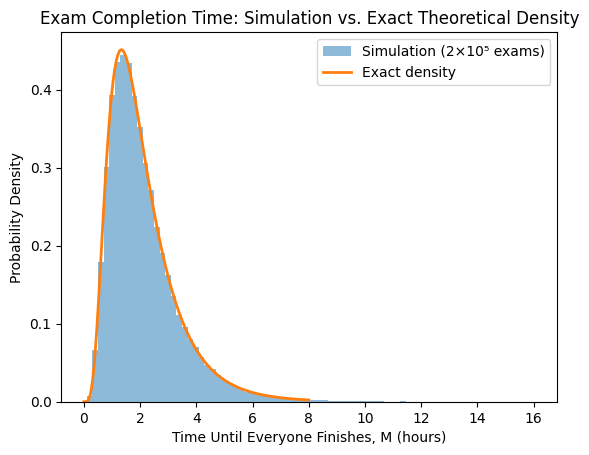

In [5]:
t_values = np.linspace(0, 8, 400)
density = []

for t in t_values:
    f = 0.0
    for i in range(n):
        term = rates[i] * np.exp(-rates[i] * t)
        for j in range(n):
            if j != i:
                term *= (1 - np.exp(-rates[j] * t))
        f += term
    density.append(f)


# Plot simulated histogram
plt.hist(M_list, bins=80, density=True, alpha=0.5, label="Simulation (2×10⁵ exams)")

# Plot theoretical density line
plt.plot(t_values, density, linewidth=2, label=r"Exact density")

plt.xlabel("Time Until Everyone Finishes, M (hours)")
plt.ylabel("Probability Density")
plt.title("Exam Completion Time: Simulation vs. Exact Theoretical Density")
plt.legend()
plt.show()

In [6]:
# Check that the finishing time of the first student does not depend on who that student is
times = np.array([
    [random.expovariate(r) for r in rates]
    for exam in range(N)
])

X = np.min(times, axis=1)        # time of the first student
first = np.argmin(times, axis=1) # Index of first student

Lambda = sum(rates)

print("Simulated mean time overall E[X]:", np.mean(X))
print("Theoretical mean time 1/Λ:", 1 / Lambda)
print("\nConditional mean time given who finished first E[X | I = i]:")

for i in range(n):
    X_given_i_first = X[first == i] # Filter the times X for exams where student 'i' finished first
    cond_mean = np.mean(X_given_i_first)
    p_first = np.mean(first == i)
    print(f"Student {i+1}: P(first) = {p_first:.4f}, E[X | first] = {cond_mean:.5f}")

Simulated mean time overall E[X]: 0.10576568614951457
Theoretical mean time 1/Λ: 0.10582010582010583

Conditional mean time given who finished first E[X | I = i]:
Student 1: P(first) = 0.3176, E[X | first] = 0.10591
Student 2: P(first) = 0.2117, E[X | first] = 0.10530
Student 3: P(first) = 0.1594, E[X | first] = 0.10644
Student 4: P(first) = 0.1263, E[X | first] = 0.10553
Student 5: P(first) = 0.1051, E[X | first] = 0.10549
Student 6: P(first) = 0.0799, E[X | first] = 0.10580


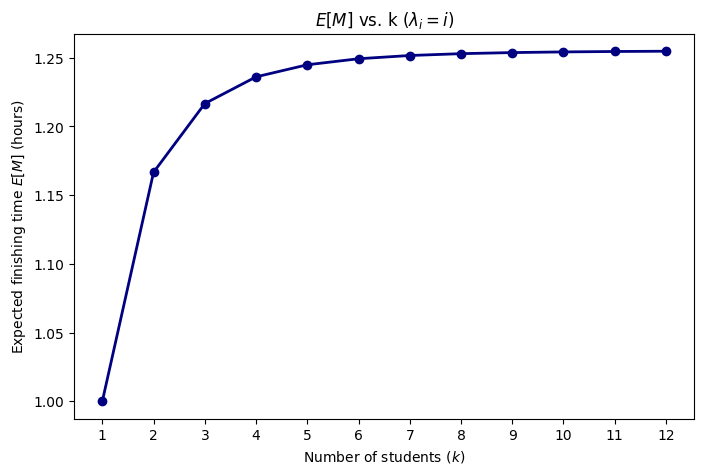

In [7]:
k_values = list(range(1, 13))
Em_values = []

for k in k_values:
    k_rates = list(range(1, k + 1))
    Em = 0
    for size in range(1, k + 1):
        for group in combinations(k_rates, size):
            total = sum(group)
            if size % 2 == 1:
                Em += 1 / total
            else:
                Em -= 1 / total
    Em_values.append(Em)


plt.figure(figsize=(8, 5))
plt.plot(k_values, Em_values, 'o-', color='navy', linewidth=2, label=r"Exact $E[M]$ for $\lambda_i = i$")

plt.xlabel("Number of students ($k$)")
plt.ylabel("Expected finishing time $E[M]$ (hours)")
plt.title(r"$E[M]$ vs. k ($\lambda_i = i$)")
plt.xticks(k_values)
plt.show()